# Part 1 — EEG decoder

Code lives in `src/decoder/`:
- `data.py` — load, filter, epoch
- `pipeline.py` — CSP + LDA, calibration, `run_subject()`
- `metrics.py` — ECE, latency

Outputs: figures go to `results/part1/figures/`; the per-subject summary and the per-trial table for Part 2 go to `results/part1/`; the trained decoders go to `logs/decoder_models/` and a run log to `logs/part1_run.log`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# work from the submission root, wherever Jupyter started
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from moabb.datasets import BNCI2014_001
from sklearn.metrics import confusion_matrix

from src.decoder.data import CLASSES
from src.decoder.pipeline import SEED, run_subject
from src.decoder.metrics import reliability_curve

OUT = Path("results/part1")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"

print(f"mne {mne.__version__}, seed {SEED}")

mne 1.12.1, seed 20260901


## Visualise the data

Sampling frequency: 250.0 Hz
Duration: 386.94 s (96735 samples)
EEG channels (22): Fz, FC3, FC1, FCz, FC2, FC4, C5, C3, C1, Cz, C2, C4, C6, CP3, CP1, CPz, CP2, CP4, P1, Pz, P2, POz


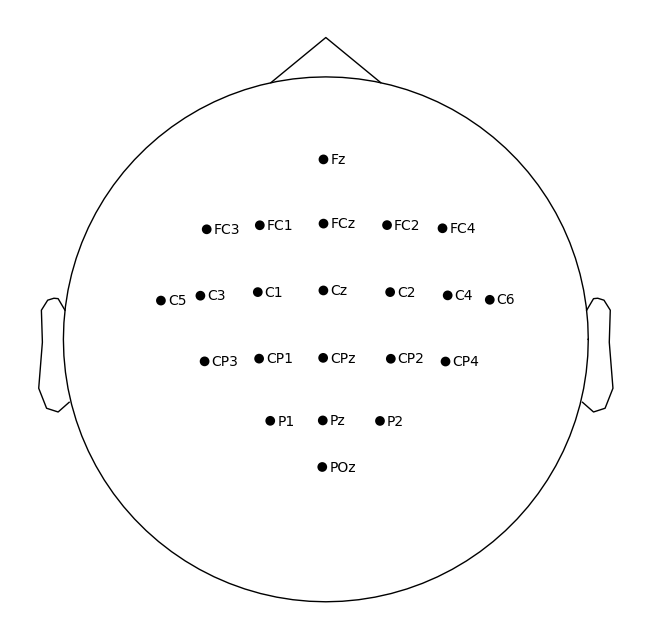

In [2]:
%matplotlib inline
mne.set_log_level("WARNING")

# subject 3, day 1, run 0
data = BNCI2014_001().get_data(subjects=[3])
raw = data[3]["0train"]["0"].copy()
raw.pick("eeg")  # drop EOG

print(f"Sampling frequency: {raw.info['sfreq']} Hz")
print(f"Duration: {raw.times[-1]:.2f} s ({len(raw.times)} samples)")
print(f"EEG channels ({raw.info['nchan']}): {', '.join(raw.ch_names)}")

fig = raw.plot_sensors(show_names=True, show=False)
fig.savefig(FIG / "sensor_layout.png", dpi=200, bbox_inches="tight")
plt.show()

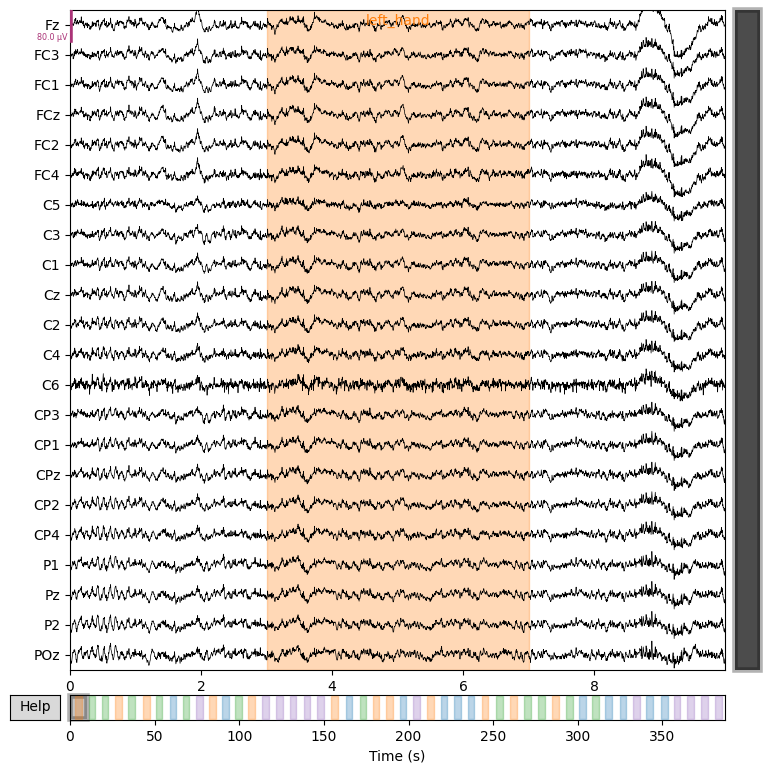

In [3]:
# interactive raw signal viewer
fig = raw.plot(duration=10.0, n_channels=22, scalings={"eeg": 40e-6}, show=True, block=False)

# understanding the data 

It contains recordings from 9 subjects performing four different imagined movements:

* Left hand
* Right hand
* Both feet
* Tongue

the reason we pick the dataset is we can map the left hand and right hand to tuen left and right etc and feet to move forward and tongue to stop.

The EEG was recorded using 22 EEG channels at a sampling rate of 250 Hz. The recordings also contain 3 EOG channels for detecting eye-related activity and a stimulus channel containing event information.

In the following code, we will inspect how MOABB loads the dataset, how the raw EEG is stored, how annotations and events identify the motor-imagery trials, and finally how the continuous EEG is converted into epochs (X) and labels (y) for machine learning.

The basic structure is:

Raw EEG → Events/Annotations → Epochs → X + y

# EEG Bandpass Filtering (8–30 Hz)

: ## Types of Brain Waves

- **Delta (δ): 0.5–4 Hz** — Active mainly during **deep sleep**.
- **Theta (θ): 4–8 Hz** — Common during **drowsiness, light sleep, and deep relaxation**.
- **Alpha (α): 8–13 Hz** — Prominent during **relaxed wakefulness**, especially with eyes closed.
- **Beta (β): 13–30 Hz** — Associated with **active thinking, concentration and during  movement and movement imagination and                               rebound when stop**.
- **Gamma (γ): 30–100 Hz** — Associated with **higher-level information processing and cognitive activity**.


also there is another brian signal **$\mu$ (mu) : 8 -12 Hz** - it associtated with movemnat imagination or performing movement. the alpha and mu has same freq range but the mu wave generate in sensori motor cortex. 

* we need to filter the $\beta$ and $\mu$ rhythm so we set the bandwidth 8-30 hz .





In [4]:
# 4th-order Butterworth, 8-30 Hz
raw.filter(8.0, 30.0, method="iir", iir_params={"order": 4, "ftype": "butter"})

<RawArray | 22 x 96735 (386.9 s), ~16.3 MiB, data loaded>

## Lebel

we map 
* 0 - left hand
* 1- right hand
* 2-feet
* 3- tongue

In [5]:
events, event_ids = mne.events_from_annotations(raw)
print("MNE ids (alphabetical):", event_ids)

# map by name, not by number
event_id_to_class_idx = {event_ids[c]: i for i, c in enumerate(CLASSES)}
for mne_id, idx in event_id_to_class_idx.items():
    print(f"MNE ID {mne_id} -> Class {idx} ({CLASSES[idx]})")

MNE ids (alphabetical): {'feet': 1, 'left_hand': 2, 'right_hand': 3, 'tongue': 4}
MNE ID 2 -> Class 0 (left_hand)
MNE ID 3 -> Class 1 (right_hand)
MNE ID 1 -> Class 2 (feet)
MNE ID 4 -> Class 3 (tongue)


## Cut trial epochs 

the t = 0s , the trial maker place the fixation cross and at t = 2s the visual cue arrow instruct the subject to imagine . so teh subject imagine the at t = 2.5 to 4.5s . we skip the initial 2.5s because the signal mainly due to eye movment (tracked in eog ).  

In [6]:
epochs = mne.Epochs(raw, events, tmin=2.5, tmax=4.5, baseline=None, preload=True, verbose=False)
X = epochs.get_data()
y = np.array([event_id_to_class_idx[e] for e in epochs.events[:, 2]])

print(f"X shape: {X.shape}  -> (trials, channels, time_points)")
print(f"Class distribution (run 0): {np.bincount(y)}")

X shape: (48, 22, 501)  -> (trials, channels, time_points)
Class distribution (run 0): [12 12 12 12]


## Run all 9 subjects

`run_subject()` loads day 1 and day 2, fits CSP + LDA on 75% of day 1, calibrates on the other 25%, then evaluates on day 2.

Latency: a 2 s window slides over 0–4 s after the cue. A trial is **censored** if it never reaches 50% confidence, or if it has no data for the long window (last trial of each run).

In [7]:
results = {s: run_subject(s) for s in range(1, 10)}

df = pd.DataFrame([r["summary"] for r in results.values()])
df.round(4).to_csv(OUT / "summary_by_subject.csv", index=False)
df.round(3)

Computing rank from data with rank=None


    Using tolerance 3.3e-05 (2.2e-16 eps * 22 dim * 6.7e+09  max singular value)


    Estimated rank (data): 22


    data: rank 22 computed from 22 data channels with 0 projectors


Reducing data rank from 22 -> 22


Estimating class=0 covariance using EMPIRICAL


... (108 outputs left out)

Done.


Estimating class=3 covariance using EMPIRICAL


Done.


,subject,raw_acc,calib_acc,kappa,raw_ece,calib_ece,median_latency,censored_fraction
0,1,0.576,0.556,0.407,0.138,0.150,2.00,0.125
1,2,0.611,0.556,0.407,0.150,0.075,3.55,0.458
2,3,0.708,0.691,0.588,0.146,0.044,2.00,0.021
3,4,0.389,0.389,0.185,0.142,0.077,4.00,1.000
4,5,0.312,0.191,-0.079,0.148,0.144,4.00,0.924
5,6,0.368,0.378,0.171,0.188,0.030,4.00,0.826
6,7,0.469,0.396,0.194,0.299,0.188,2.00,0.024
7,8,0.535,0.497,0.329,0.091,0.094,3.70,0.403
8,9,0.378,0.337,0.116,0.157,0.063,4.00,0.990


In [8]:
# mean ± std (latency not averaged: 5 subjects sit on the 4 s cap)
cols = ["raw_acc", "calib_acc", "kappa", "raw_ece", "calib_ece", "censored_fraction"]
df[cols].agg(["mean", "std"]).round(3)

,raw_acc,calib_acc,kappa,raw_ece,calib_ece,censored_fraction
mean,0.483,0.443,0.258,0.162,0.096,0.530
std,0.133,0.147,0.197,0.057,0.053,0.415


### Raw ECE as the report counts it

The table above scores the raw (uncalibrated) LDA confidence against the **raw** prediction, which gives a mean raw ECE of 0.162. The report's Table 2 scores the same raw confidence against the **calibrated** prediction (the decision the wheelchair actually uses), which gives 0.196. Both are computed below, so the numbers can be matched to the report. The calibrated ECE (0.096) is the same either way.

In [9]:
from src.decoder.metrics import compute_ece

raw_ece_report = {s: compute_ece(r["raw_proba"].max(1), r["cal_proba"].argmax(1), r["y_test"])
                  for s, r in results.items()}
ece_compare = pd.DataFrame({
    "raw ECE (raw prediction)": df.set_index("subject")["raw_ece"],
    "raw ECE (calibrated prediction, report)": pd.Series(raw_ece_report),
    "calibrated ECE": df.set_index("subject")["calib_ece"],
})
ece_compare.loc["mean"] = ece_compare.mean()
ece_compare.round(3)

,raw ECE (raw prediction),"raw ECE (calibrated prediction, report)",calibrated ECE
1,0.138,0.158,0.150
2,0.150,0.167,0.075
3,0.146,0.164,0.044
4,0.142,0.131,0.077
5,0.148,0.268,0.144
6,0.188,0.190,0.030
7,0.299,0.371,0.188
8,0.091,0.122,0.094
9,0.157,0.192,0.063
mean,0.162,0.196,0.096


## Hand-off to Part 2

Part 2 needs the decoder's behaviour **trial by trial**, not just per subject. This cell writes one row per day-2 trial to `results/part1/decoder_traces.csv`: the cued and predicted class, whether it was right, the raw and calibrated confidence, and the decision latency. Each test session is 6 runs of 48 trials, so the run number is the trial index divided by 48.

It also saves each subject's trained decoder (CSP + LDA, and the Platt-calibrated version) to `logs/decoder_models/`, and the summary numbers to `logs/part1_run.log`.

In [10]:
import joblib

# one row per test trial
rows = []
for s, r in results.items():
    raw_conf = r["raw_proba"].max(1)
    cal_conf = r["cal_proba"].max(1)
    pred = r["cal_proba"].argmax(1)
    for i, y in enumerate(r["y_test"]):
        rows.append({
            "subject": s, "trial_idx": i, "session": "1test", "run": i // 48,
            "true_class": int(y), "pred_class": int(pred[i]),
            "true_class_name": CLASSES[y], "pred_class_name": CLASSES[pred[i]],
            "correct": int(pred[i] == y),
            "p_max": float(raw_conf[i]), "p_calibrated": float(cal_conf[i]),
            "decision_latency_s": float(r["latencies"][i]),
            "latency_censored": int(r["censored"][i]),
        })
traces = pd.DataFrame(rows)
traces.to_csv(OUT / "decoder_traces.csv", index=False)

# trained decoders
model_dir = Path("logs/decoder_models")
model_dir.mkdir(parents=True, exist_ok=True)
for s, r in results.items():
    joblib.dump({"raw": r["pipe"], "calibrated": r["cal_model"]}, model_dir / f"subject_{s:02d}.joblib")

# run log
log_lines = [
    "Part 1 run log",
    f"mne {mne.__version__}, seed {SEED}",
    "",
    df.round(4).to_string(index=False),
    "",
    f"mean calibrated accuracy {df.calib_acc.mean():.3f}, mean kappa {df.kappa.mean():.3f}",
    f"mean ECE: calibrated {df.calib_ece.mean():.3f}, raw (raw prediction) {df.raw_ece.mean():.3f}, "
    f"raw (calibrated prediction, as in the report) {np.mean(list(raw_ece_report.values())):.3f}",
    f"censored trials: {int(traces.latency_censored.sum())} of {len(traces)}",
    f"wrote {OUT / 'decoder_traces.csv'} ({len(traces)} rows) and {len(results)} models to {model_dir}",
]
Path("logs/part1_run.log").write_text("\n".join(log_lines) + "\n", encoding="utf-8")
print("\n".join(log_lines))

Part 1 run log
mne 1.12.1, seed 20260901

 subject  raw_acc  calib_acc   kappa  raw_ece  calib_ece  median_latency  censored_fraction
       1   0.5764     0.5556  0.4074   0.1379     0.1498            2.00             0.1250
       2   0.6111     0.5556  0.4074   0.1501     0.0747            3.55             0.4583
       3   0.7083     0.6910  0.5880   0.1463     0.0445            2.00             0.0208
       4   0.3889     0.3889  0.1852   0.1417     0.0769            4.00             1.0000
       5   0.3125     0.1910 -0.0787   0.1478     0.1441            4.00             0.9236
       6   0.3681     0.3785  0.1713   0.1884     0.0297            4.00             0.8264
       7   0.4688     0.3958  0.1944   0.2990     0.1884            2.00             0.0243
       8   0.5347     0.4965  0.3287   0.0909     0.0938            3.70             0.4028
       9   0.3785     0.3368  0.1157   0.1565     0.0628            4.00             0.9896

mean calibrated accuracy 0.443, mean 

## Figures

### Results table

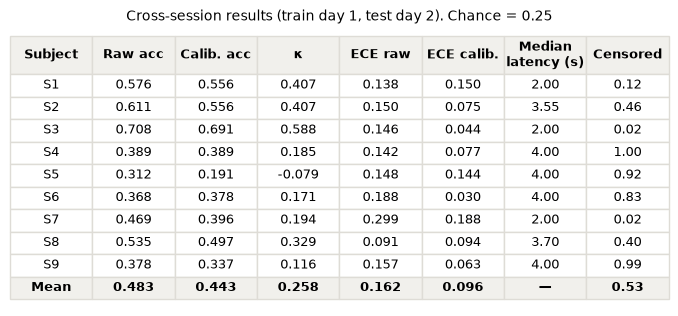

In [11]:
rows = [[f"S{int(r.subject)}", f"{r.raw_acc:.3f}", f"{r.calib_acc:.3f}", f"{r.kappa:.3f}",
         f"{r.raw_ece:.3f}", f"{r.calib_ece:.3f}", f"{r.median_latency:.2f}",
         f"{r.censored_fraction:.2f}"] for r in df.itertuples()]
m = df.mean()
rows.append(["Mean", f"{m.raw_acc:.3f}", f"{m.calib_acc:.3f}", f"{m.kappa:.3f}",
             f"{m.raw_ece:.3f}", f"{m.calib_ece:.3f}", "—", f"{m.censored_fraction:.2f}"])
headers = ["Subject", "Raw acc", "Calib. acc", "κ", "ECE raw", "ECE calib.",
           "Median\nlatency (s)", "Censored"]

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axis("off")
tbl = ax.table(cellText=rows, colLabels=headers, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.35)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#dedcd6")
    if r == 0:
        cell.set_height(cell.get_height() * 1.7)
    if r in (0, len(rows)):
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#f1f0ec")
ax.set_title("Cross-session results (train day 1, test day 2). Chance = 0.25", fontsize=10)
fig.savefig(FIG / "fig1_results_table.png", dpi=300, bbox_inches="tight")
plt.show()

### Calibration — subject 3 reliability + ECE for every subject

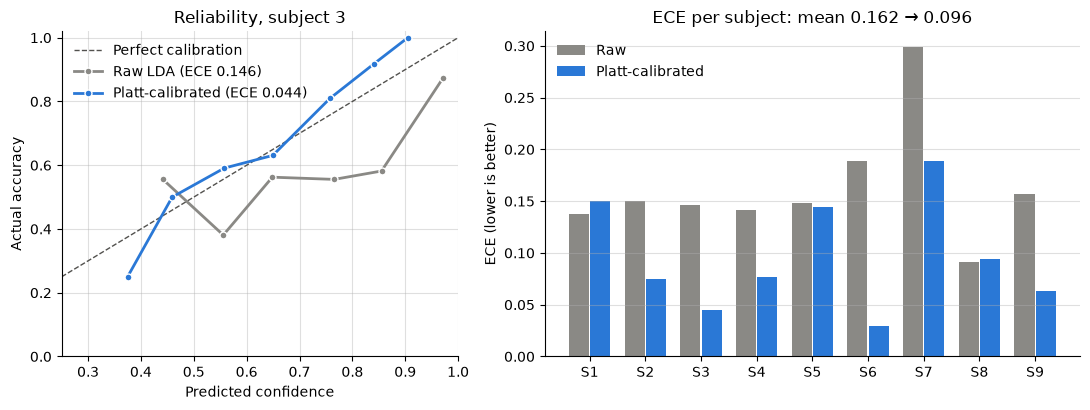

In [12]:
r3 = results[3]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.35]})

# reliability diagram
ax1.plot([0.25, 1], [0.25, 1], "--", color="#52514e", lw=1, label="Perfect calibration")
for name, proba, color, key in [("Raw LDA", r3["raw_proba"], GREY, "raw_ece"),
                                ("Platt-calibrated", r3["cal_proba"], BLUE, "calib_ece")]:
    c, a = reliability_curve(proba.max(1), proba.argmax(1), r3["y_test"])
    ax1.plot(c, a, "o-", color=color, lw=2, ms=5, mec="white",
             label=f"{name} (ECE {r3['summary'][key]:.3f})")
ax1.set(xlim=(0.25, 1), ylim=(0, 1.02), title="Reliability, subject 3",
        xlabel="Predicted confidence", ylabel="Actual accuracy")
ax1.legend(frameon=False)
ax1.grid(alpha=0.4)

# ECE before / after
x = np.arange(len(df))
ax2.bar(x - 0.19, df.raw_ece, 0.36, color=GREY, label="Raw")
ax2.bar(x + 0.19, df.calib_ece, 0.36, color=BLUE, label="Platt-calibrated")
ax2.set_xticks(x, [f"S{s}" for s in df.subject])
ax2.set(ylabel="ECE (lower is better)",
        title=f"ECE per subject: mean {df.raw_ece.mean():.3f} → {df.calib_ece.mean():.3f}")
ax2.legend(frameon=False)
ax2.grid(axis="y", alpha=0.4)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "fig2_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

### Confusion matrices — where the errors go

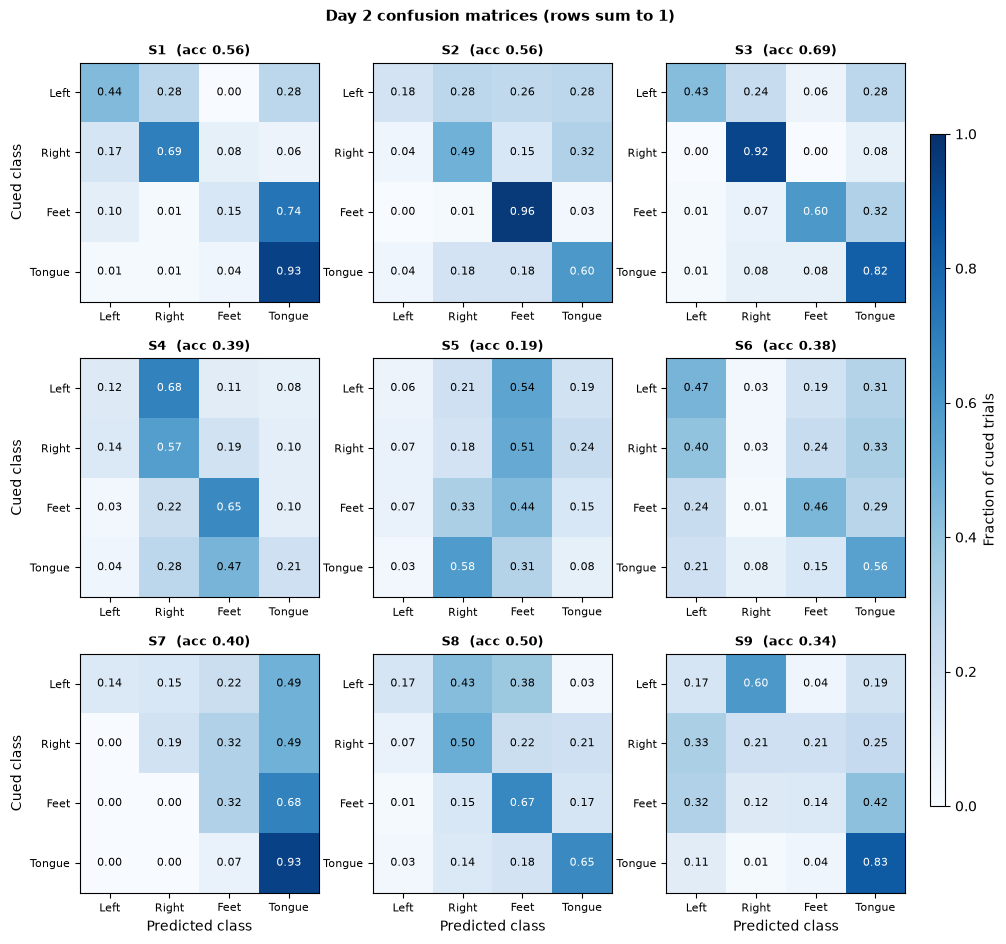

In [13]:
labels = ["Left", "Right", "Feet", "Tongue"]
fig, axes = plt.subplots(3, 3, figsize=(10, 9.6))

for ax, (s, r) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(r["y_test"], r["cal_proba"].argmax(1), normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4), labels, fontsize=8)
    ax.set_yticks(range(4), labels, fontsize=8)
    ax.set_title(f"S{s}  (acc {r['summary']['calib_acc']:.2f})", fontsize=9, fontweight="bold")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.55 else "black")

for ax in axes[:, 0]:
    ax.set_ylabel("Cued class")
for ax in axes[-1]:
    ax.set_xlabel("Predicted class")

fig.tight_layout(rect=(0, 0, 0.92, 0.96))
fig.colorbar(im, cax=fig.add_axes([0.93, 0.15, 0.015, 0.7]), label="Fraction of cued trials")
fig.suptitle("Day 2 confusion matrices (rows sum to 1)", fontsize=11, fontweight="bold")
fig.savefig(FIG / "fig3_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

### Decision latency

Censored trials are not counted as decided, so each curve stops at (1 − censored fraction).

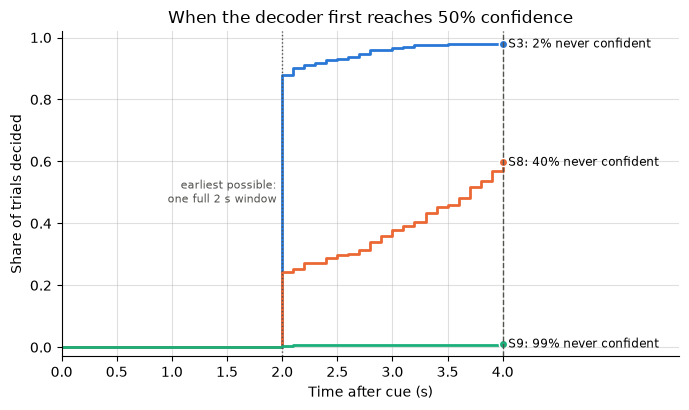

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.2))

for s, color in [(3, BLUE), (8, ORANGE), (9, GREEN)]:
    r = results[s]
    n = len(r["latencies"])
    done = np.sort(r["latencies"][~r["censored"]])
    t = np.r_[0, done, 4.0]
    frac = np.r_[0, np.arange(1, len(done) + 1) / n, len(done) / n]
    ax.step(t, frac, where="post", color=color, lw=2)
    ax.plot(4.0, frac[-1], "o", color=color, mec="white")
    ax.text(4.05, frac[-1], f"S{s}: {r['censored'].mean():.0%} never confident", va="center", fontsize=8.5)

ax.axvline(2.0, color="#52514e", ls=":", lw=1)
ax.text(1.95, 0.5, "earliest possible:\none full 2 s window", ha="right", va="center",
        fontsize=8, color="#52514e")
ax.axvline(4.0, color="#52514e", ls="--", lw=1)
ax.set(xlim=(0, 5.6), ylim=(-0.03, 1.02), xticks=np.arange(0, 4.01, 0.5),
       xlabel="Time after cue (s)", ylabel="Share of trials decided",
       title="When the decoder first reaches 50% confidence")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.4)
fig.tight_layout()
fig.savefig(FIG / "fig4_latency.png", dpi=300, bbox_inches="tight")
plt.show()

### Appendix — CSP patterns (subject 3)

Sanity check: patterns should sit over motor cortex (C3, Cz, C4). Uses the decoder's own CSP, no refit.

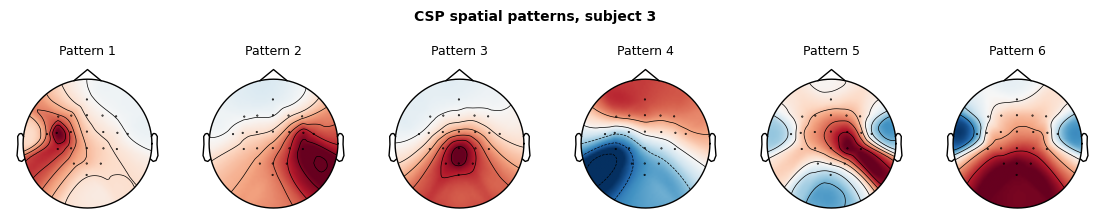

In [15]:
patterns = results[3]["pipe"].named_steps["csp"].patterns_
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for i, ax in enumerate(axes):
    mne.viz.plot_topomap(patterns[i], raw.info, axes=ax, show=False, cmap="RdBu_r")
    ax.set_title(f"Pattern {i + 1}", fontsize=9)
fig.suptitle("CSP spatial patterns, subject 3", fontsize=10, fontweight="bold")
fig.savefig(FIG / "figA1_csp_patterns.png", dpi=300, bbox_inches="tight")
plt.show()